In [16]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [17]:
from google.colab import files

uploaded = files.upload()

Saving vgg6_assignment_solution.zip to vgg6_assignment_solution.zip


In [18]:
import zipfile
import os

zip_path = "/content/vgg6_assignment_solution.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

project_path = "/content/vgg6_assignment_solution"
os.chdir(project_path)

print("Current folder:", os.getcwd())
print("Files:", os.listdir())

Current folder: /content/vgg6_assignment_solution
Files: ['test_best.py', 'README.md', '.gitignore', 'vgg6_assignment_solution.zip', 'runs', 'src', 'requirements.txt', 'train.py', 'plot_results.py', 'data', '__pycache__', 'configs']


In [19]:
import torch
import torchvision
import numpy
import matplotlib

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", numpy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("GPU:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
NumPy: 2.1.3
Matplotlib: 3.10.0
GPU: True


In [20]:
!python train.py --epochs 1 --batch-size 128 --run-name test_run --workers 2

epoch 001/1 train_loss=1.6323 train_acc=39.66% val_loss=1.3802 val_acc=50.38%
{
  "run_name": "test_run",
  "best_val_acc": 50.38,
  "best_epoch": 1,
  "last_val_acc": 50.38,
  "wall_seconds": 19.164976666000257
}


In [21]:
!python train.py --config configs/baseline.json

epoch 001/30 train_loss=1.6323 train_acc=39.66% val_loss=1.3802 val_acc=50.38%
epoch 002/30 train_loss=1.3122 train_acc=53.05% val_loss=1.3579 val_acc=52.94%
epoch 003/30 train_loss=1.1759 train_acc=57.90% val_loss=1.2898 val_acc=55.90%
epoch 004/30 train_loss=1.0921 train_acc=61.15% val_loss=1.1852 val_acc=61.32%
epoch 005/30 train_loss=1.0236 train_acc=63.98% val_loss=1.1965 val_acc=59.72%
epoch 006/30 train_loss=0.9739 train_acc=65.89% val_loss=1.2535 val_acc=61.14%
epoch 007/30 train_loss=0.9344 train_acc=67.33% val_loss=0.8789 val_acc=69.86%
epoch 008/30 train_loss=0.9004 train_acc=68.44% val_loss=0.9608 val_acc=68.74%
epoch 009/30 train_loss=0.8709 train_acc=69.42% val_loss=0.8892 val_acc=70.16%
epoch 010/30 train_loss=0.8474 train_acc=70.24% val_loss=0.9096 val_acc=69.32%
epoch 011/30 train_loss=0.8298 train_acc=71.00% val_loss=0.8733 val_acc=70.42%
epoch 012/30 train_loss=0.7998 train_acc=72.10% val_loss=0.8397 val_acc=71.06%
epoch 013/30 train_loss=0.7850 train_acc=72.59% val_

In [22]:
!python plot_results.py --run-dir runs/baseline

Saved five local plots in runs/baseline


train_loss.png


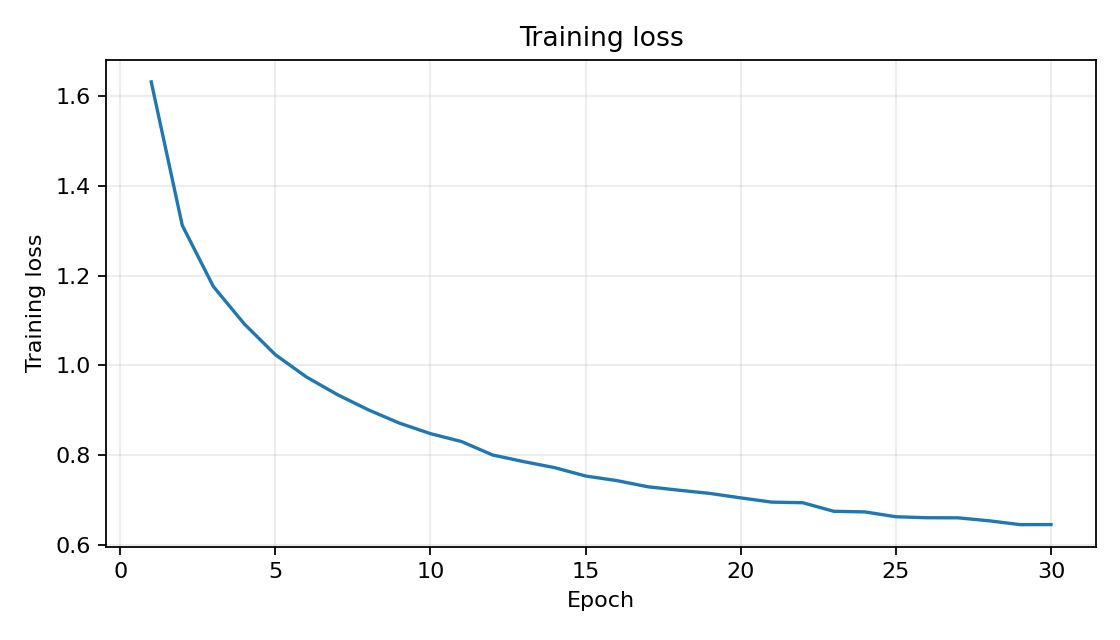

train_acc.png


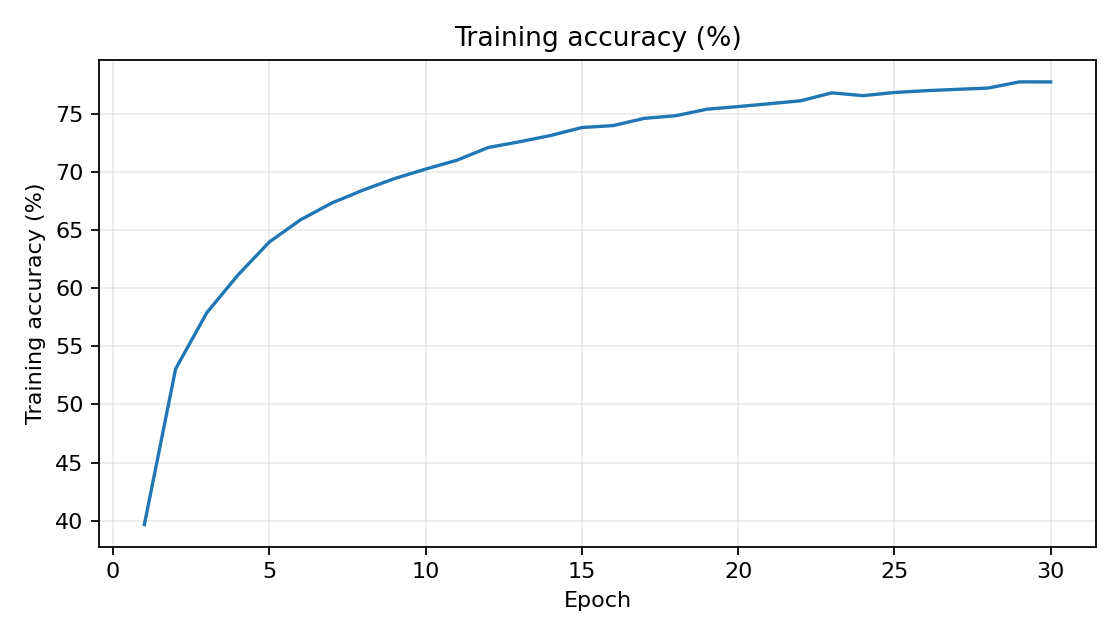

val_loss.png


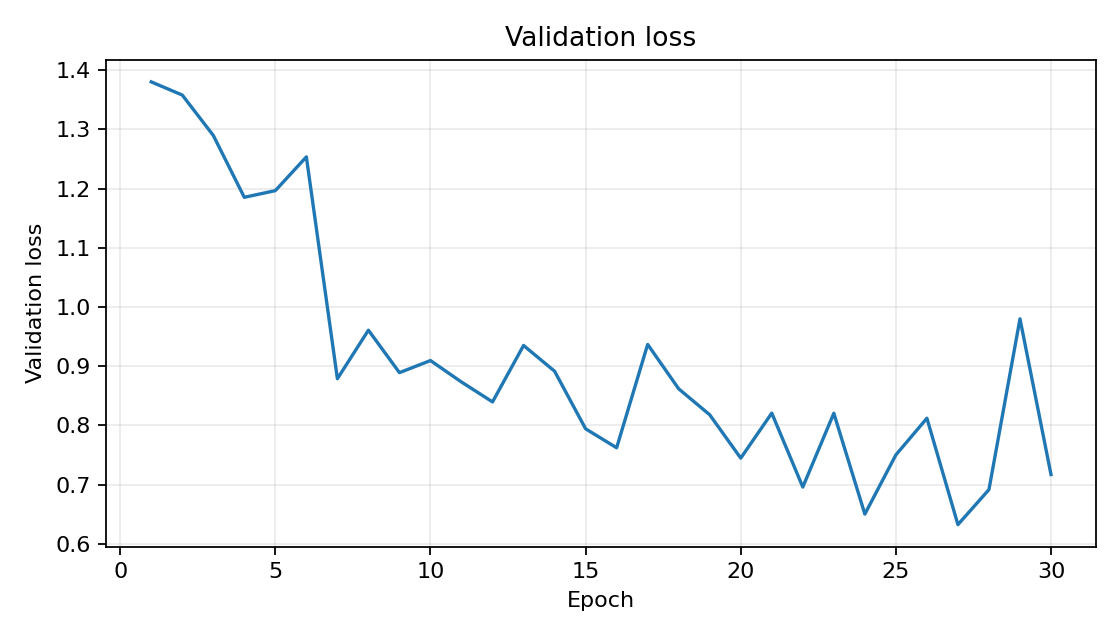

val_acc.png


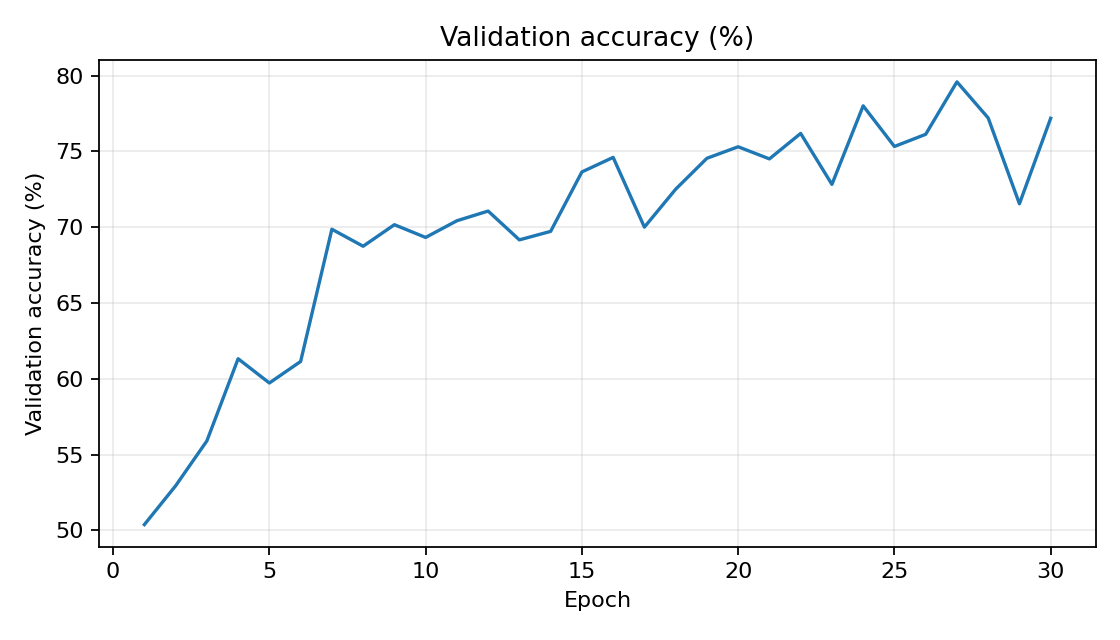

val_acc_scatter.png


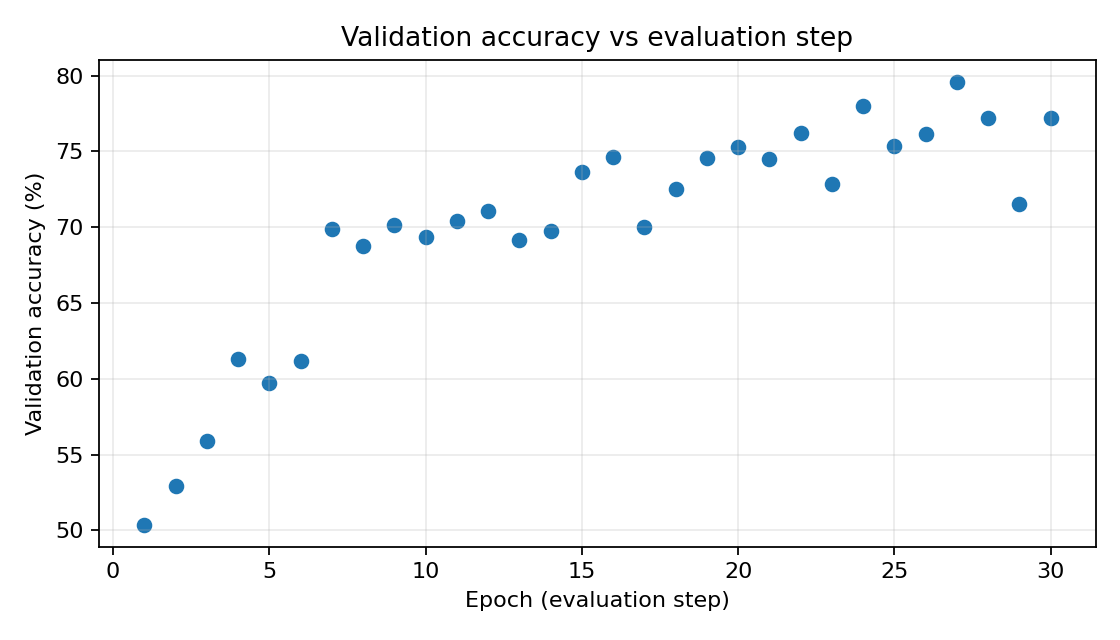

In [23]:
from IPython.display import display, Image
import os

plot_dir = "runs/baseline"

for filename in [
    "train_loss.png",
    "train_acc.png",
    "val_loss.png",
    "val_acc.png",
    "val_acc_scatter.png"
]:
    print(filename)
    display(Image(filename=os.path.join(plot_dir, filename)))

In [24]:
!python test_best.py --checkpoint runs/baseline/best.pt

{
  "test_top1_accuracy_percent": 78.87,
  "test_cross_entropy_loss": 0.6382161448955536,
  "selected_validation_accuracy_percent": 79.58,
  "selected_epoch": 27
}


In [25]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/vgg6_results",
    "zip",
    "/content/vgg6_assignment_solution/runs/baseline"
)

files.download("/content/vgg6_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
%cd /content/vgg6_assignment_solution
!python test_best.py --checkpoint runs/baseline/best.pt

/content
{
  "test_top1_accuracy_percent": 78.87,
  "test_cross_entropy_loss": 0.6382161448955536,
  "selected_validation_accuracy_percent": 79.58,
  "selected_epoch": 27
}


In [27]:
%pip install -q wandb

In [28]:
import wandb

wandb.login()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: keerthana_cs25m512 (keerthana_cs25m512-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [29]:
import wandb

print("W&B version:", wandb.__version__)
print("Authenticated:", wandb.api.api_key is not None)

W&B version: 0.28.1
Authenticated: True


In [30]:
%%writefile /content/vgg6_assignment_solution/configs/sweep.yaml
program: train.py
method: bayes

metric:
  name: best_val_acc
  goal: maximize

parameters:
  activation:
    values: [relu, sigmoid, tanh, silu, gelu]

  optimizer:
    values: [sgd, nesterov, adam, adagrad, rmsprop, nadam]

  lr:
    values: [0.0001, 0.001, 0.01]

  batch-size:
    values: [64, 128, 256]

  epochs:
    values: [15, 30]

  momentum:
    value: 0.9

  weight-decay:
    value: 0.0005

  seed:
    value: 42

command:
  - ${env}
  - ${interpreter}
  - ${program}
  - --wandb
  - --run-name
  - sweep-run
  - ${args}

Overwriting /content/vgg6_assignment_solution/configs/sweep.yaml


In [31]:
%cd /content/vgg6_assignment_solution
!cat configs/sweep.yaml
!wandb sweep configs/sweep.yaml

/content
program: train.py
method: bayes

metric:
  name: best_val_acc
  goal: maximize

parameters:
  activation:
    values: [relu, sigmoid, tanh, silu, gelu]

  optimizer:
    values: [sgd, nesterov, adam, adagrad, rmsprop, nadam]

  lr:
    values: [0.0001, 0.001, 0.01]

  batch-size:
    values: [64, 128, 256]

  epochs:
    values: [15, 30]

  momentum:
    value: 0.9

  weight-decay:
    value: 0.0005

  seed:
    value: 42

command:
  - ${env}
  - ${interpreter}
  - ${program}
  - --wandb
  - --run-name
  - sweep-run
  - ${args}
wandb: Creating sweep from: configs/sweep.yaml
wandb: Creating sweep with ID: epwiqqv6
wandb: View sweep at: https://wandb.ai/keerthana_cs25m512-indian-institute-of-technology-madras/uncategorized/sweeps/epwiqqv6
wandb: Run sweep agent with: wandb agent keerthana_cs25m512-indian-institute-of-technology-madras/uncategorized/epwiqqv6


In [32]:
!wandb agent keerthana_cs25m512-indian-institute-of-technology-madras/uncategorized/i62zqf4a --count 10

wandb: Starting wandb agent 🕵️
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
2026-10-29 02:47:56,491 - wandb.wandb_agent - INFO - Running runs: []
2026-10-29 02:47:57,076 - wandb.wandb_agent - INFO - Agent received command: run
2026-10-29 02:47:57,076 - wandb.wandb_agent - INFO - Agent starting run with config:
	activation: gelu
	batch-size: 64
	epochs: 15
	lr: 0.0001
	momentum: 0.9
	optimizer: sgd
	seed: 42
	weight-decay: 0.0005
2026-10-29 02:47:57,078 - wandb.wandb_agent - INFO - About to run command: /usr/bin/env python train.py --wandb --run-name sweep-run --activation=gelu --batch-size=64 --epochs=15 --lr=0.0001 --momentum=0.9 --optimizer=sgd --seed=42 --weight-decay=0.0005
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: keerthana_cs25m512 (keerthana_cs25m512-indian-institute-of-technology-madras) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: 